In [2]:
from transformers import pipeline

clip = pipeline(
   task="zero-shot-image-classification",
   model="openai/clip-vit-base-patch32",
   device=0
)
labels = ["a photo of a cat", "a photo of a dog", "a photo of a car", 'not a cat']
clip("http://images.cocodataset.org/val2017/000000039769.jpg", candidate_labels=labels, hidden_states=True)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[{'score': 0.8501213192939758, 'label': 'not a cat'},
 {'score': 0.14874367415905, 'label': 'a photo of a cat'},
 {'score': 0.0007471922435797751, 'label': 'a photo of a car'},
 {'score': 0.0003878016723319888, 'label': 'a photo of a dog'}]

In [3]:
from transformers import CLIPModel, CLIPTokenizer
import torch

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")

inputs = tokenizer(
    ["a photo of a cat"],
    return_tensors="pt"
)

with torch.no_grad():
    outputs = model.text_model(
        **inputs,
        output_hidden_states=True
    )

hidden_states = outputs.hidden_states

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [26]:
import torch
from transformers import CLIPModel, AutoTokenizer

name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(
    name,
    attn_implementation="eager",
).eval()

tokenizer = AutoTokenizer.from_pretrained(name)

text = "not a cat"

inputs = tokenizer(text, return_tensors="pt")

tokens = tokenizer.convert_ids_to_tokens(inputs.input_ids[0])

print(tokens)

with torch.no_grad():
    out = model.text_model(
        **inputs,
        output_attentions=True,
    )

attentions = out.attentions

print(len(attentions))
print(attentions[0].shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

['<|startoftext|>', 'not</w>', 'a</w>', 'cat</w>', '<|endoftext|>']
12
torch.Size([1, 8, 5, 5])


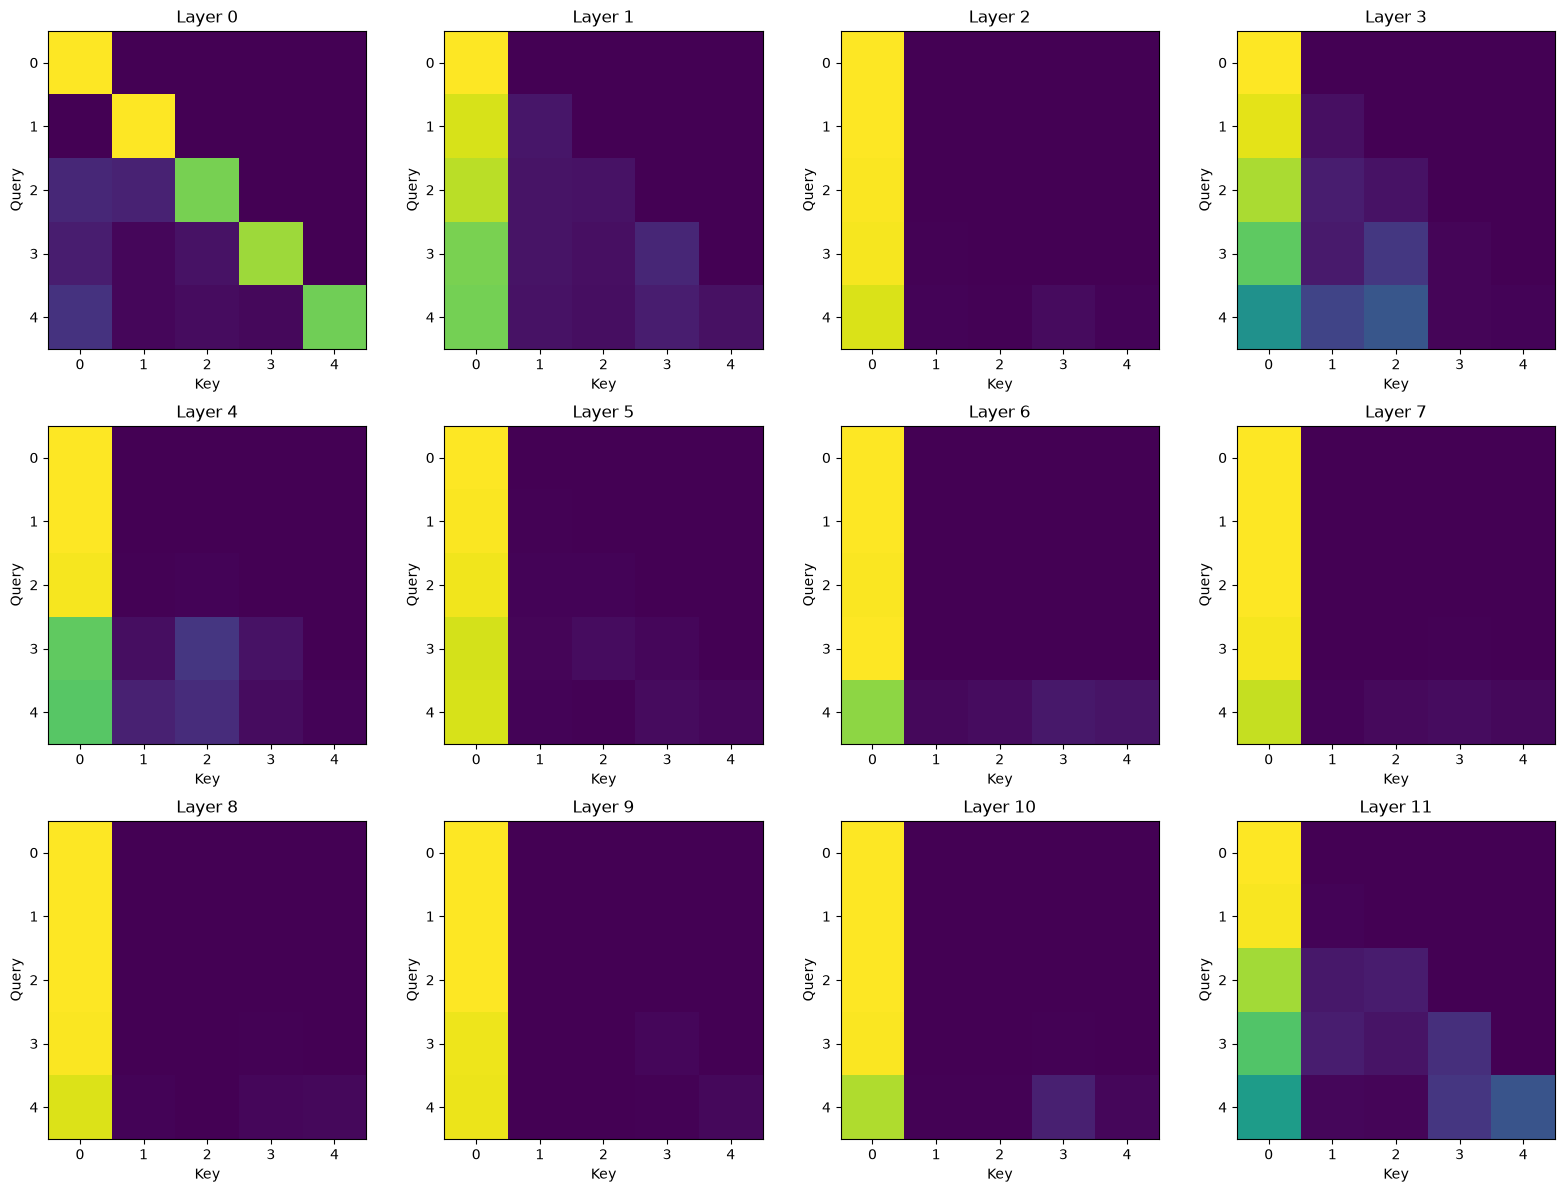

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, ax in enumerate(axes.flat):
    att = attentions[i][0, 6].detach().cpu().numpy()

    im = ax.imshow(att)
    ax.set_title(f"Layer {i}")
    ax.set_xlabel("Key")
    ax.set_ylabel("Query")

plt.tight_layout()
plt.show()